# Part 3 - SLAM Global Localization: Accumulation of Uncertainty Through Drift

This notebook demonstrates odometry drift and uncertainty accumulation in VIO-based SLAM systems using ARP_utility_code sensors.

In [2]:
# Imports

import numpy as np
import matplotlib.pyplot as plt

from manifpy import SE2

import sys
sys.path.insert(0, '/workspace/Python/Relative-localisation-tutorial/src')

from config import TrajectoryConfig, VIOConfig
from trajectory import generate_trajectory, sgal3_to_se2_poses
from vio_sensor import simulate_vio_odometry
from relative_pose import compute_relative_poses

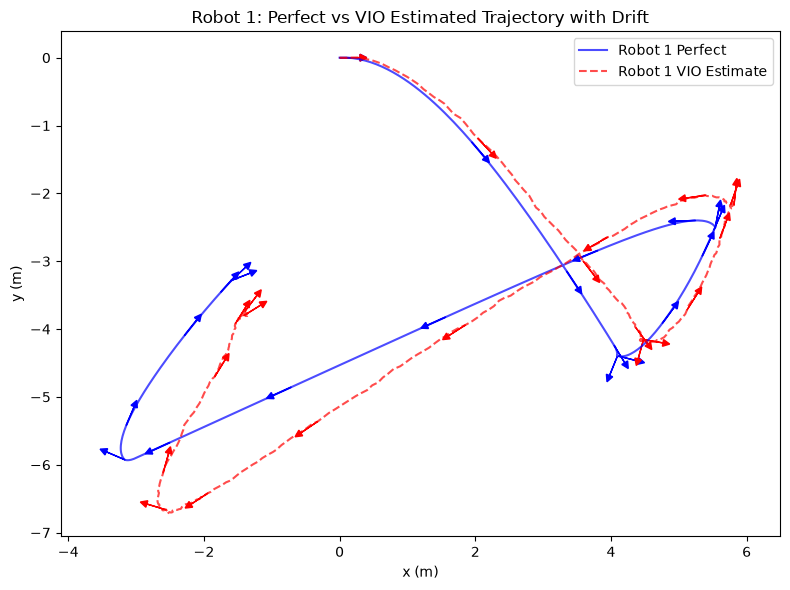

In [3]:
# Parameters for robot 1 trajectory + VIO simulation

traj_config = TrajectoryConfig(duration=50.0, timestep=0.1, seed=42)
vio_config = VIOConfig(sig_v=0.1, sig_w=0.05)

traj_robot1 = generate_trajectory(
    duration=traj_config.duration,
    timestep=traj_config.timestep,
    seed=traj_config.seed
)

poses_robot1_perfect = sgal3_to_se2_poses(traj_robot1.X_RRi)
poses_robot1_noisy, _ = simulate_vio_odometry(traj_robot1, vio_config)

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.plot(poses_robot1_perfect[:, 0], poses_robot1_perfect[:, 1], 'b-', label='Robot 1 Perfect', alpha=0.7)
ax.plot(poses_robot1_noisy[:, 0], poses_robot1_noisy[:, 1], 'r--', label='Robot 1 VIO Estimate', alpha=0.7)

arrow_len = 0.3
step = max(1, len(poses_robot1_perfect) // 20)
for i in range(0, len(poses_robot1_perfect), step):
    x_i, y_i, theta_i = poses_robot1_perfect[i]
    dx = arrow_len * np.cos(theta_i)
    dy = arrow_len * np.sin(theta_i)
    ax.arrow(x_i, y_i, dx, dy, head_width=0.1, head_length=0.1, fc='b', ec='b')

for i in range(0, len(poses_robot1_noisy), step):
    x_i, y_i, theta_i = poses_robot1_noisy[i]
    dx = arrow_len * np.cos(theta_i)
    dy = arrow_len * np.sin(theta_i)
    ax.arrow(x_i, y_i, dx, dy, head_width=0.1, head_length=0.1, fc='r', ec='r')

ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.axis('equal')
ax.legend()
ax.set_title('Robot 1: Perfect vs VIO Estimated Trajectory with Drift')

plt.tight_layout()
plt.show()

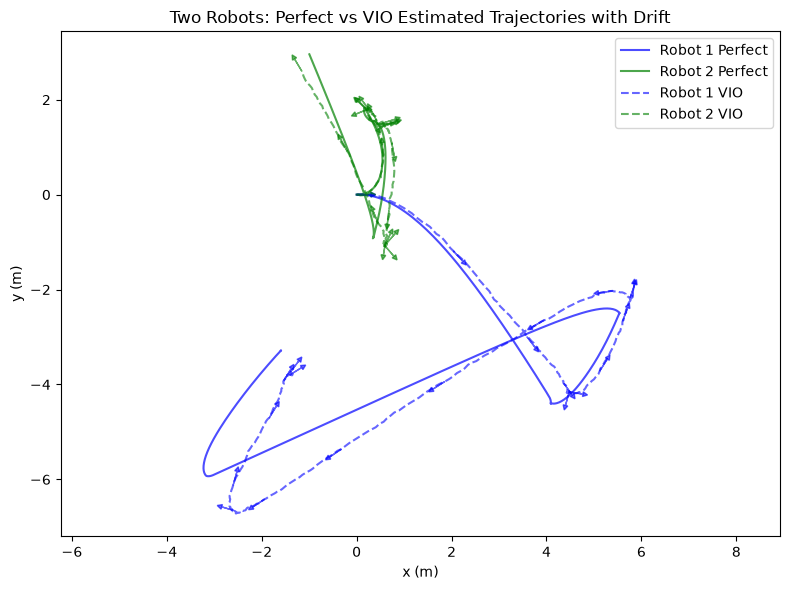

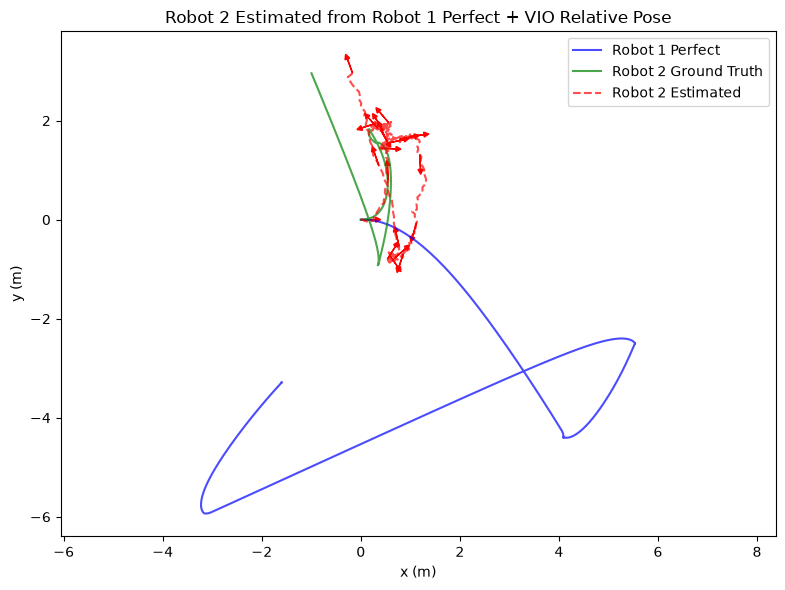

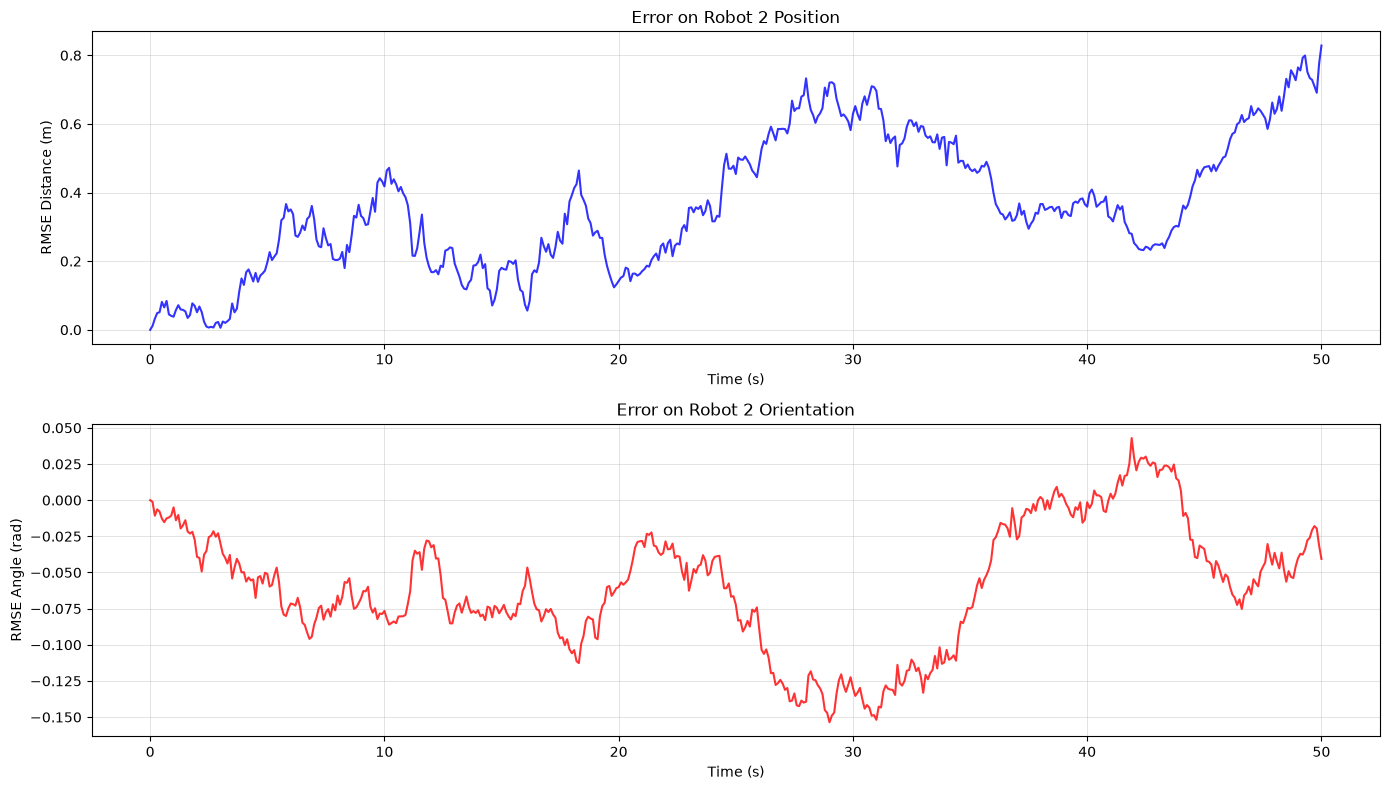

In [4]:
# Parameters for robot 2 trajectory + VIO simulation

traj_config_robot1 = TrajectoryConfig(duration=50.0, timestep=0.1, seed=42)
vio_config_robot1 = VIOConfig(sig_v=0.1, sig_w=0.05)

traj_robot1 = generate_trajectory(
    duration=traj_config_robot1.duration,
    timestep=traj_config_robot1.timestep,
    seed=traj_config_robot1.seed
)

poses_robot1_perfect = sgal3_to_se2_poses(traj_robot1.X_RRi)
poses_robot1_noisy, _ = simulate_vio_odometry(traj_robot1, vio_config_robot1)

traj_config_robot2 = TrajectoryConfig(duration=50.0, timestep=0.1, seed=123, start_x=2.0, start_y=2.0, start_theta=np.deg2rad(45))
vio_config_robot2 = VIOConfig(sig_v=0.1, sig_w=0.05)

traj_robot2 = generate_trajectory(
    duration=traj_config_robot2.duration,
    timestep=traj_config_robot2.timestep,
    seed=traj_config_robot2.seed
)

poses_robot2_perfect = sgal3_to_se2_poses(traj_robot2.X_RRi)
poses_robot2_noisy, _ = simulate_vio_odometry(traj_robot2, vio_config_robot2)

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.plot(poses_robot1_perfect[:, 0], poses_robot1_perfect[:, 1], 'b-', label='Robot 1 Perfect', alpha=0.7)
ax.plot(poses_robot2_perfect[:, 0], poses_robot2_perfect[:, 1], 'g-', label='Robot 2 Perfect', alpha=0.7)
ax.plot(poses_robot1_noisy[:, 0], poses_robot1_noisy[:, 1], 'b--', label='Robot 1 VIO', alpha=0.6)
ax.plot(poses_robot2_noisy[:, 0], poses_robot2_noisy[:, 1], 'g--', label='Robot 2 VIO', alpha=0.6)

arrow_len = 0.3
step = max(1, len(poses_robot1_perfect) // 20)
for i in range(0, len(poses_robot1_noisy), step):
    x_i, y_i, theta_i = poses_robot1_noisy[i]
    dx = arrow_len * np.cos(theta_i)
    dy = arrow_len * np.sin(theta_i)
    ax.arrow(x_i, y_i, dx, dy, head_width=0.1, head_length=0.1, fc='b', ec='b', alpha=0.6)
for i in range(0, len(poses_robot2_noisy), step):
    x_i, y_i, theta_i = poses_robot2_noisy[i]
    dx = arrow_len * np.cos(theta_i)
    dy = arrow_len * np.sin(theta_i)
    ax.arrow(x_i, y_i, dx, dy, head_width=0.1, head_length=0.1, fc='g', ec='g', alpha=0.6)

ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.axis('equal')
ax.legend()
ax.set_title('Two Robots: Perfect vs VIO Estimated Trajectories with Drift')

plt.tight_layout()
plt.show()

# Compute relative pose from VIO estimates
relative_poses_vio = compute_relative_poses(poses_robot1_noisy, poses_robot2_noisy)

# Estimate robot 2 global pose: T_OR2_est = T_OR1_perfect * T_R1R2_VIO
se2_robot1_perfect = [SE2(p[0], p[1], p[2]) for p in poses_robot1_perfect]
relative_poses_vio_se2 = [SE2(p[0], p[1], p[2]) for p in relative_poses_vio]

poses_robot2_estimated = np.zeros_like(poses_robot1_perfect)
for i in range(len(se2_robot1_perfect)):
    T_OR2_est = se2_robot1_perfect[i].compose(relative_poses_vio_se2[i])
    poses_robot2_estimated[i, 0] = T_OR2_est.x()
    poses_robot2_estimated[i, 1] = T_OR2_est.y()
    poses_robot2_estimated[i, 2] = T_OR2_est.angle()

# Plot: Robot 2 estimation from robot 1 perfect + VIO relative pose
fig2, ax2 = plt.subplots(1, 1, figsize=(8, 6))
ax2.plot(poses_robot1_perfect[:, 0], poses_robot1_perfect[:, 1], 'b-', label='Robot 1 Perfect', alpha=0.7)
ax2.plot(poses_robot2_perfect[:, 0], poses_robot2_perfect[:, 1], 'g-', label='Robot 2 Ground Truth', alpha=0.7)
ax2.plot(poses_robot2_estimated[:, 0], poses_robot2_estimated[:, 1], 'r--', label='Robot 2 Estimated', alpha=0.7)

arrow_len = 0.3
step = max(1, len(poses_robot2_estimated) // 20)
for i in range(0, len(poses_robot2_estimated), step):
    x_i, y_i, theta_i = poses_robot2_estimated[i]
    dx = arrow_len * np.cos(theta_i)
    dy = arrow_len * np.sin(theta_i)
    ax2.arrow(x_i, y_i, dx, dy, head_width=0.1, head_length=0.1, fc='r', ec='r')

ax2.set_xlabel('x (m)')
ax2.set_ylabel('y (m)')
ax2.axis('equal')
ax2.legend()
ax2.set_title('Robot 2 Estimated from Robot 1 Perfect + VIO Relative Pose')

plt.tight_layout()
plt.show()

# RMSE Analysis
t = np.arange(len(relative_poses_vio)) * traj_config_robot1.timestep

pos_error = np.sqrt((poses_robot2_estimated[:, 0] - poses_robot2_perfect[:, 0])**2 + 
                   (poses_robot2_estimated[:, 1] - poses_robot2_perfect[:, 1])**2)
angle_error = poses_robot2_estimated[:, 2] - poses_robot2_perfect[:, 2]
angle_error = (angle_error + np.pi) % (2 * np.pi) - np.pi

fig3, ax3 = plt.subplots(2, 1, figsize=(14, 8))

ax3[0].plot(t, pos_error, 'b-', alpha=0.8)
ax3[0].set_xlabel('Time (s)')
ax3[0].set_ylabel('RMSE Distance (m)')
ax3[0].set_title('Error on Robot 2 Position')
ax3[0].grid(True)

ax3[1].plot(t, angle_error, 'r-', alpha=0.8)
ax3[1].set_xlabel('Time (s)')
ax3[1].set_ylabel('RMSE Angle (rad)')
ax3[1].set_title('Error on Robot 2 Orientation')
ax3[1].grid(True)

plt.tight_layout()
plt.show()

# Cell 5: Conclusion on drift

## Summary of Key Findings

### 1. VIO Odometry Drift
- VIO sensors provide pose estimates that accumulate uncertainty over time
- Gaussian noise in velocity and angular velocity measurements propagates through integration
- Error grows monotonically as the robot moves - this is known as *drift*
- The drift appears as a progressive deviation from the ground truth trajectory

### 2. Uncertainty Accumulation Mechanism
- At each time step, VIO integrates noisy velocity measurements: `p_{k+1} = p_k + v_k * dt`
- Velocity noise is added at each integration step, causing errors to accumulate
- Angular velocity noise causes orientation drift, which in turn rotates the velocity estimate
- The cumulative effect leads to increasingly large pose estimation errors over time

### 3. Comparison with Part 1 & 2
- In Part 1 (VICON), we had perfect global measurements - no drift
- In Part 2 (UWB), we had periodic global corrections based on range measurements
- Here in Part 3, VIO provides *only* local measurements, so errors accumulate without correction
- SLAM systems that use only odometry will exhibit this same drift behavior unless they incorporates loop closures or external constraints

### 4. Key Takeaway
VIO and similar inertial sensors provide high-frequency pose estimates but suffer from drift due to integration of noisy measurements. To obtain accurate long-term localization, these must be combined with absolute position measurements (e.g., GPS, visual landmarks, UWB anchors) to correct the accumulated error.